In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

In [2]:
df = pd.read_csv("bestsellers with categories.csv")
display(df.head())
print('Розмір датасету:', df.shape)
print(f"Відповідь: датасет містить дані про {df.shape[0]} записів книг у рейтингу.")

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


Розмір датасету: (550, 7)
Відповідь: датасет містить дані про 550 записів книг у рейтингу.


In [ ]:
# 1. Визначення розміру цін

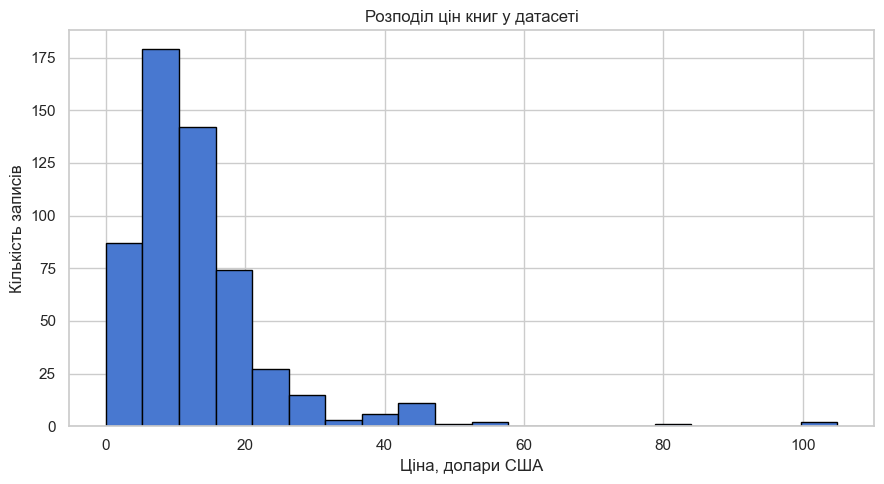

Відповідь: максимальна ціна — 105
Відповідь: мінімальна ціна — 0
Відповідь: середня ціна — 13.10
Відповідь: медіанна ціна — 11.0


In [6]:
df["Price"].plot(kind="hist", bins=20, figsize=(9, 5), edgecolor="black")
plt.title("Розподіл цін книг у датасеті")
plt.xlabel("Ціна, долари США")
plt.ylabel("Кількість записів")
plt.tight_layout()
plt.show()

max_price = df["Price"].max()
min_price = df["Price"].min()
mean_price = df["Price"].mean()
median_price = df["Price"].median()
print(f"Відповідь: максимальна ціна — {max_price}")
print(f"Відповідь: мінімальна ціна — {min_price}")
print(f"Відповідь: середня ціна — {mean_price:.2f}")
print(f"Відповідь: медіанна ціна — {median_price}")

In [ ]:
# 2. Пошук та сортування

In [14]:
highest_rating = df["User Rating"].max()
print("Відповідь: найвищий рейтинг у датасеті —", highest_rating)
print("Відповідь: кількість книг із таким рейтингом —", int((df["User Rating"] == highest_rating).sum()))

most_reviewed = df.loc[df["Reviews"].idxmax()]
print("Відповідь: найбільше відгуків має книга:", most_reviewed["Name"],
      "| автор:", most_reviewed["Author"], "| відгуків:", int(most_reviewed["Reviews"]))

books_2015 = df[df["Year"] == 2015]
most_expensive_2015 = books_2015.loc[books_2015["Price"].idxmax()]
print("Відповідь: найдорожча книга 2015 року:", most_expensive_2015["Name"],
      "| ціна:", most_expensive_2015["Price"])

fiction_2010 = df[(df["Genre"] == "Fiction") & (df["Year"] == 2010)]
print("Відповідь: книг жанру Fiction у 2010 році —", len(fiction_2010))

rated_49_2010_2011 = df[(df["User Rating"] == 4.9) & (df["Year"].isin([2010, 2011]))]
print("Відповідь: книг із рейтингом 4.9 у 2010 та 2011 роках —", len(rated_49_2010_2011))

sorted_2015_under8 = df[(df["Year"] == 2015) & (df["Price"] < 8)].sort_values("Price")
display(sorted_2015_under8)
if not sorted_2015_under8.empty:
    print("Відповідь: остання книга у відсортованому списку —",
          sorted_2015_under8.iloc[-1]["Name"],
          "| ціна:", sorted_2015_under8.iloc[-1]["Price"])
else:
    print("Умова не повернула жодного рядка.")

Відповідь: найвищий рейтинг у датасеті — 4.9
Відповідь: кількість книг із таким рейтингом — 52
Відповідь: найбільше відгуків має книга: Where the Crawdads Sing | автор: Delia Owens | відгуків: 87841
Відповідь: найдорожча книга 2015 року: Publication Manual of the American Psychological Association, 6th Edition | ціна: 46
Відповідь: книг жанру Fiction у 2010 році — 20
Відповідь: книг із рейтингом 4.9 у 2010 та 2011 роках — 1


,Name,Author,User Rating,Reviews,Price,Year,Genre
507,To Kill a Mockingbird,Harper Lee,4.8,26234,0,2015,Fiction
210,Laugh-Out-Loud Jokes for Kids,Rob Elliott,4.6,6990,4,2015,Non Fiction
206,Knock-Knock Jokes for Kids,Rob Elliott,4.5,3673,4,2015,Non Fiction
111,First 100 Words,Roger Priddy,4.7,17323,4,2015,Non Fiction
123,Giraffes Can't Dance,Giles Andreae,4.8,14038,4,2015,Fiction
54,Creative Haven Creative Cats Coloring Book (Ad...,Marjorie Sarnat,4.8,4022,4,2015,Non Fiction
63,Dear Zoo: A Lift-the-Flap Book,Rod Campbell,4.8,10922,5,2015,Fiction
89,Dover Creative Haven Art Nouveau Animal Design...,Marty Noble,4.6,2134,5,2015,Non Fiction
478,The Very Hungry Caterpillar,Eric Carle,4.9,19546,5,2015,Fiction
201,Killing Reagan: The Violent Assault That Chang...,Bill O'Reilly,4.6,5235,5,2015,Non Fiction


Відповідь: остання книга у відсортованому списку — Old School (Diary of a Wimpy Kid #10) | ціна: 7


In [ ]:
# 3. Агрегування за жанром

In [20]:
genre_prices = df.groupby("Genre").agg(price_min=("Price", "min"), price_max=("Price", "max"))
display(genre_prices)
for genre in ["Fiction", "Non Fiction"]:
    if genre in genre_prices.index:
        print(f"Відповідь: максимальна ціна для {genre}: {genre_prices.loc[genre, 'price_max']}")
        print(f"Відповідь: мінімальна ціна для {genre}: {genre_prices.loc[genre, 'price_min']}")

,price_min,price_max
Genre,,
Fiction,0,82
Non Fiction,0,105


Відповідь: максимальна ціна для Fiction: 82
Відповідь: мінімальна ціна для Fiction: 0
Відповідь: максимальна ціна для Non Fiction: 105
Відповідь: мінімальна ціна для Non Fiction: 0


In [ ]:
# 4. Кількість книг для кожного автора

In [22]:
books_by_author = df.groupby("Author").agg(book_count=("Name", "count"))
print("Розмірність таблиці кількості книг за авторами:", books_by_author.shape)
display(books_by_author.sort_values("book_count", ascending=False).head(10))

max_author_count = books_by_author["book_count"].max()
top_authors = books_by_author[books_by_author["book_count"] == max_author_count]
print("Відповідь: автор(и) з найбільшою кількістю книг:")
display(top_authors)
print("Відповідь: кількість книг такого автора —", int(max_author_count))

Розмірність таблиці кількості книг за авторами: (248, 1)


,book_count
Author,
Jeff Kinney,12
Gary Chapman,11
Suzanne Collins,11
Rick Riordan,11
American Psychological Association,10
Gallup,9
Dr. Seuss,9
Rob Elliott,8
Eric Carle,7


Відповідь: автор(и) з найбільшою кількістю книг:


,book_count
Author,
Jeff Kinney,12


Відповідь: кількість книг такого автора — 12


In [23]:
# 5.Середній рейтинг для кожного автора

In [25]:
rating_by_author = df.groupby("Author").agg(avg_rating=("User Rating", "mean"))
min_avg_rating = rating_by_author["avg_rating"].min()
lowest_rated_authors = rating_by_author[rating_by_author["avg_rating"] == min_avg_rating]
print("Відповідь: автор(и) з найнижчим середнім рейтингом:")
display(lowest_rated_authors)
print(f"Відповідь: мінімальний середній рейтинг — {min_avg_rating:.3f}")

Відповідь: автор(и) з найнижчим середнім рейтингом:


,avg_rating
Author,
Donna Tartt,3.9


Відповідь: мінімальний середній рейтинг — 3.900


In [26]:
# 6. Об'єднання кількості книг і середнього рейтингу, сортування за зростанням

In [27]:
authors_summary = pd.concat([books_by_author, rating_by_author], axis=1)
authors_sorted = authors_summary.sort_values(["book_count", "avg_rating"], ascending=[True, True])
display(authors_sorted.head(10))
print("Відповідь: перший автор у відсортованому списку —", authors_sorted.index[0])

,book_count,avg_rating
Author,,
Muriel Barbery,1,4.0
Chris Cleave,1,4.1
Ian K. Smith M.D.,1,4.1
Pierre Dukan,1,4.1
Elizabeth Strout,1,4.2
Geneen Roth,1,4.2
Mark Hyman M.D.,1,4.2
Mark Twain,1,4.2
Michael Wolff,1,4.2


Відповідь: перший автор у відсортованому списку — Muriel Barbery


In [28]:
# Візуалізації: 4 графіки різних типів

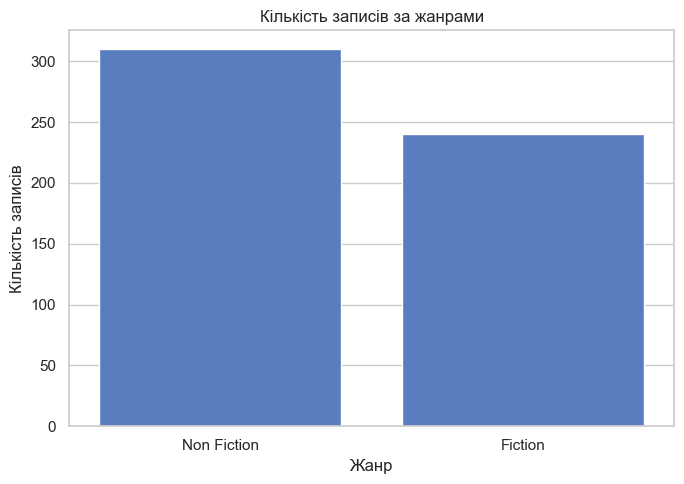

In [30]:
# Графік 1: кількість записів за жанром
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Genre")
plt.title("Кількість записів за жанрами")
plt.xlabel("Жанр")
plt.ylabel("Кількість записів")
plt.tight_layout()
plt.show()

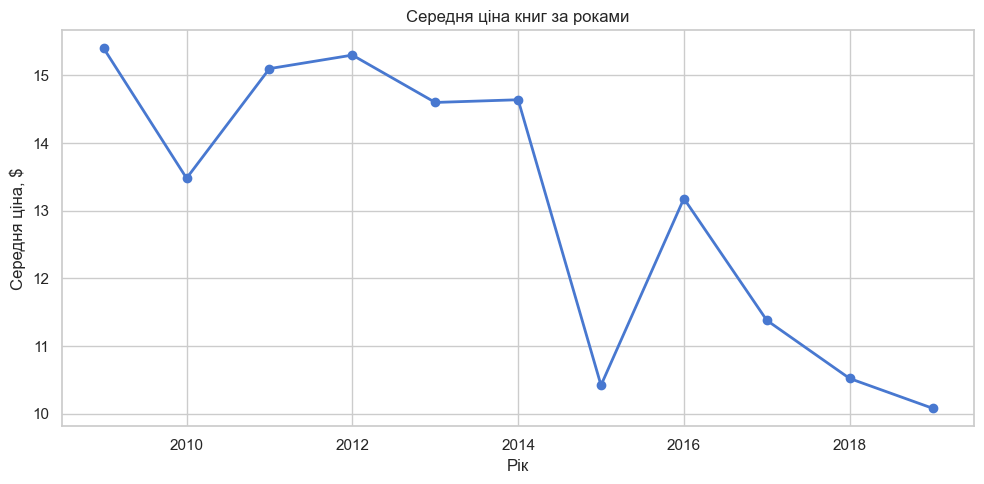

In [31]:
# Графік 2: середня ціна за роком
year_price = df.groupby("Year")["Price"].mean()
plt.figure(figsize=(10, 5))
year_price.plot(kind="line", marker="o", linewidth=2)
plt.title("Середня ціна книг за роками")
plt.xlabel("Рік")
plt.ylabel("Середня ціна, $")
plt.tight_layout()
plt.show()

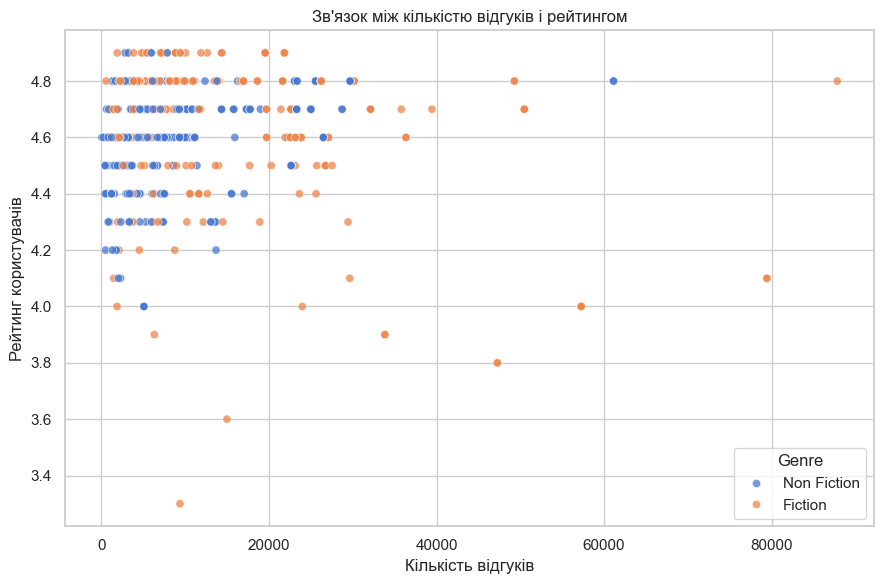

In [32]:
# Графік 3: рейтинг проти кількості відгуків
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Reviews", y="User Rating", hue="Genre", alpha=0.75)
plt.title("Зв'язок між кількістю відгуків і рейтингом")
plt.xlabel("Кількість відгуків")
plt.ylabel("Рейтинг користувачів")
plt.tight_layout()
plt.show()

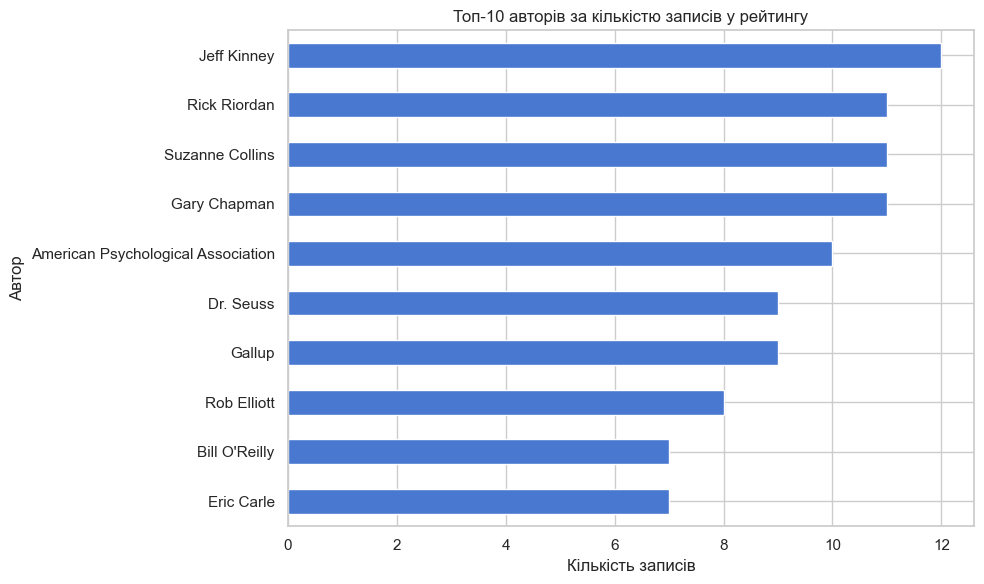

In [33]:
# Графік 4: 10 авторів із найбільшою кількістю записів у рейтингу
top10 = books_by_author.sort_values("book_count", ascending=False).head(10).sort_values("book_count")
plt.figure(figsize=(10, 6))
top10["book_count"].plot(kind="barh")
plt.title("Топ-10 авторів за кількістю записів у рейтингу")
plt.xlabel("Кількість записів")
plt.ylabel("Автор")
plt.tight_layout()
plt.show()